In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, VotingClassifier, BaggingClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

WATER_CSV = 'water_potability.csv'
TELCO_CSV = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'

# Activity 1: Voting and Bagging

## Task 1: Load the data

Shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
5,5.584087,188.313324,28748.687739,7.544869,326.678363,280.467916,8.399735,54.917862,2.559708,0
6,10.223862,248.071735,28749.716544,7.513408,393.663396,283.651634,13.789695,84.603556,2.672989,0
7,8.635849,203.361523,13672.091764,4.563009,303.309771,474.607645,12.363817,62.798309,4.401425,0
8,NaN,118.988579,14285.583854,7.804174,268.646941,389.375566,12.706049,53.928846,3.595017,0
9,11.180284,227.231469,25484.508491,9.077200,404.041635,563.885481,17.927806,71.976601,4.370562,0



Missing values:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Potability distribution:
Potability
0    1998
1    1278
Name: count, dtype: int64
Potability
0    0.61
1    0.39
Name: proportion, dtype: float64


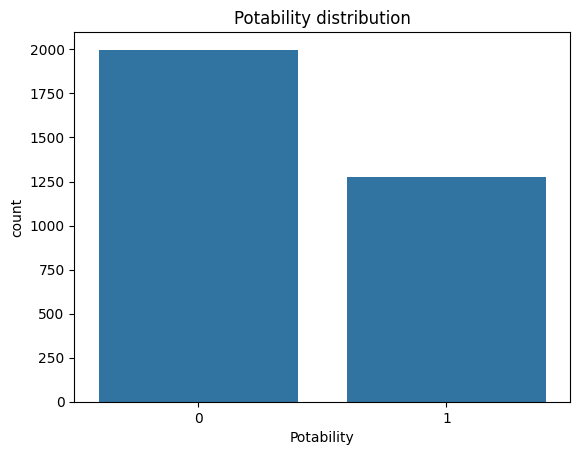

In [2]:
water = pd.read_csv(WATER_CSV)

print("Shape:", water.shape)
display(water.head(10))

print("\nMissing values:")
print(water.isnull().sum())

print("\nPotability distribution:")
print(water['Potability'].value_counts())
print(water['Potability'].value_counts(normalize=True).round(3))

sns.countplot(data=water, x='Potability')
plt.title('Potability distribution')
plt.show()

## Task 2: Stratified 80/20 split

In [3]:
X = water.drop('Potability', axis=1)
y = water['Potability']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print("Train class ratio:", y_train.mean().round(3), "| Test class ratio:", y_test.mean().round(3))

(2620, 9) (656, 9)
Train class ratio: 0.39 | Test class ratio: 0.39


## Task 3: Fill missing values

In [4]:
train_medians = X_train.median()
print(train_medians[['ph', 'Sulfate', 'Trihalomethanes']])

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("Missing after filling (train/test):", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

ph                   7.035037
Sulfate            333.073546
Trihalomethanes     66.565709
dtype: float64
Missing after filling (train/test): 0 0


## Task 4: Single models and the voting ensembles

In [5]:
lr  = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
svc = make_pipeline(StandardScaler(), SVC(probability=True, random_state=42))
rf  = RandomForestClassifier(n_estimators=100, random_state=42)

estimators = [('lr', lr), ('svc', svc), ('rf', rf)]

voting_hard = VotingClassifier(estimators, voting='hard')
voting_soft = VotingClassifier(estimators, voting='soft')

for m in (lr, svc, rf, voting_hard, voting_soft):
    m.fit(X_train, y_train)

## Task 5: Bagging, pasting and a single decision tree

In [6]:
def make_bag(n, bootstrap):
    return BaggingClassifier(
        DecisionTreeClassifier(random_state=42),
        n_estimators=n, max_samples=0.5, bootstrap=bootstrap, random_state=42
    )

bag_10    = make_bag(10, True)
bag_100   = make_bag(100, True)
paste_100 = make_bag(100, False)      # pasting: sampling without replacement
single_tree = DecisionTreeClassifier(random_state=42)

for m in (bag_10, bag_100, paste_100, single_tree):
    m.fit(X_train, y_train)

## Task 6: Compare all models on the test set

In [7]:
models = {
    'Logistic Regression': lr,
    'SVC': svc,
    'Random Forest': rf,
    'Decision Tree (single)': single_tree,
    'Voting (hard)': voting_hard,
    'Voting (soft)': voting_soft,
    'Bagging (10 trees)': bag_10,
    'Bagging (100 trees)': bag_100,
    'Pasting (100 trees)': paste_100,
}

rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    rows.append({
        'Model': name,
        'Accuracy':  accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall':    recall_score(y_test, pred),
        'F1-score':  f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index('Model').round(4)
display(results.sort_values('Accuracy', ascending=False))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Voting (hard),0.6738,0.7838,0.2266,0.3515
Pasting (100 trees),0.6723,0.6454,0.3555,0.4584
Voting (soft),0.6707,0.7222,0.2539,0.3757
SVC,0.6707,0.7041,0.2695,0.3898
Random Forest,0.6631,0.6446,0.3047,0.4138
Bagging (100 trees),0.6494,0.6048,0.2930,0.3947
Bagging (10 trees),0.6387,0.5736,0.2891,0.3844
Logistic Regression,0.6098,0.0000,0.0000,0.0000
Decision Tree (single),0.5960,0.4813,0.4531,0.4668


Best model by accuracy: Voting (hard)


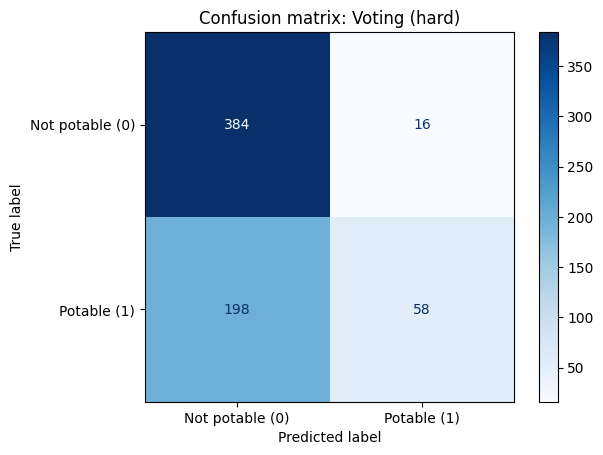

In [8]:
best_name = results['Accuracy'].idxmax()
print("Best model by accuracy:", best_name)

ConfusionMatrixDisplay.from_estimator(models[best_name], X_test, y_test,
                                      display_labels=['Not potable (0)', 'Potable (1)'], cmap='Blues')
plt.title(f'Confusion matrix: {best_name}')
plt.show()

In [9]:
singles = ['Logistic Regression', 'SVC', 'Random Forest', 'Decision Tree (single)']
ensembles = [n for n in results.index if n not in singles]

best_single = results.loc[singles, 'Accuracy'].idxmax()
best_ens = results.loc[ensembles, 'Accuracy'].idxmax()
s_acc, e_acc = results.loc[best_single, 'Accuracy'], results.loc[best_ens, 'Accuracy']

print(f"Best single model : {best_single} ({s_acc:.4f})")
print(f"Best ensemble     : {best_ens} ({e_acc:.4f})")
print("Voting/bagging beat the best single model." if e_acc > s_acc
      else "No voting/bagging ensemble beat the best single model.")

Best single model : SVC (0.6707)
Best ensemble     : Voting (hard) (0.6738)
Voting/bagging beat the best single model.


# Activity 2: Boosting

## Task 1: Load the data

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No



Missing values (NaN):
none

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


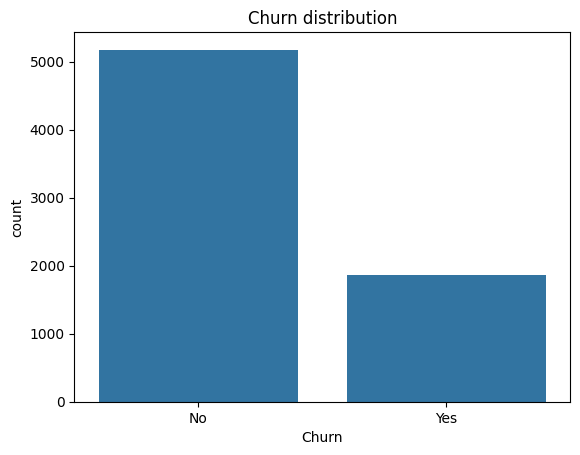

In [10]:
telco = pd.read_csv(TELCO_CSV)

print("Shape:", telco.shape)
display(telco.head(10))

print("\nMissing values (NaN):")
print(telco.isnull().sum()[lambda s: s > 0] if telco.isnull().sum().sum() else "none")

print("\nChurn distribution:")
print(telco['Churn'].value_counts())
print(telco['Churn'].value_counts(normalize=True).round(3))

sns.countplot(data=telco, x='Churn')
plt.title('Churn distribution')
plt.show()

## Task 2: TotalCharges

In [11]:
telco['TotalCharges'] = pd.to_numeric(telco['TotalCharges'], errors='coerce')

blank = telco[telco['TotalCharges'].isnull()]
print("Rows with blank TotalCharges:", len(blank))
display(blank[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])
print("All of them have tenure == 0:", (blank['tenure'] == 0).all())

Rows with blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


All of them have tenure == 0: True


In [12]:
telco['TotalCharges'] = telco['TotalCharges'].fillna(0)
print("Remaining NaN in TotalCharges:", telco['TotalCharges'].isnull().sum())

Remaining NaN in TotalCharges: 0


## Task 3: Drop ID, encode the target, one-hot encode, split

In [13]:
telco = telco.drop('customerID', axis=1)
telco['Churn'] = telco['Churn'].map({'Yes': 1, 'No': 0})

cat_cols = telco.select_dtypes(include='object').columns.tolist()
print("Categorical columns:", cat_cols)

telco_enc = pd.get_dummies(telco, columns=cat_cols, drop_first=True, dtype=int)

X = telco_enc.drop('Churn', axis=1)
y = telco_enc['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print("Churn rate train/test:", y_train.mean().round(3), y_test.mean().round(3))

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
(5634, 30) (1409, 30)
Churn rate train/test: 0.265 0.265


## Task 4: Default boosting models

In [14]:
gb  = GradientBoostingClassifier(random_state=42)
ada = AdaBoostClassifier(random_state=42)
xgb_default = XGBClassifier(random_state=42)

for m in (gb, ada, xgb_default):
    m.fit(X_train, y_train)

def evaluate(model, X, y):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {
        'Accuracy':  accuracy_score(y, pred),
        'Precision': precision_score(y, pred, zero_division=0),
        'Recall':    recall_score(y, pred),
        'F1-score':  f1_score(y, pred),
        'ROC-AUC':   roc_auc_score(y, proba),
    }

default_results = pd.DataFrame({
    'GradientBoosting': evaluate(gb, X_test, y_test),
    'AdaBoost': evaluate(ada, X_test, y_test),
    'XGBoost (default)': evaluate(xgb_default, X_test, y_test),
}).T.round(4)
display(default_results)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
GradientBoosting,0.7984,0.6552,0.5080,0.5723,0.8422
AdaBoost,0.8048,0.6623,0.5401,0.5950,0.8407
XGBoost (default),0.7764,0.5891,0.5214,0.5532,0.8183


## Task 5: Tune XGBClassifier with GridSearchCV

2 × 2 × 2 × 2 = 16 combinations × 5 folds = 80 fits.

In [15]:
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0],
}

grid = GridSearchCV(
    XGBClassifier(random_state=42),
    param_grid, cv=5, scoring='f1', n_jobs=-1, verbose=1
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1-score:", round(grid.best_score_, 4))

xgb_tuned = grid.best_estimator_

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
Best CV F1-score: 0.5884


## Task 6: Default vs tuned XGBoost on the test set

In [16]:
comparison = pd.DataFrame({
    'XGBoost (default)': evaluate(xgb_default, X_test, y_test),
    'XGBoost (tuned)':   evaluate(xgb_tuned, X_test, y_test),
}).T.round(4)
display(comparison)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
XGBoost (default),0.7764,0.5891,0.5214,0.5532,0.8183
XGBoost (tuned),0.7984,0.6490,0.5241,0.5799,0.8466


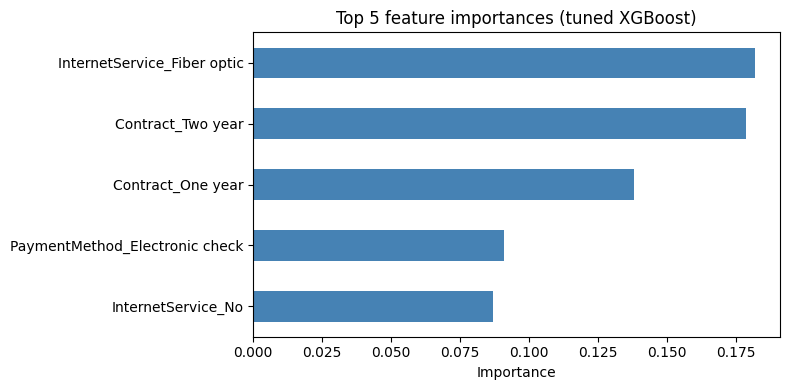

In [17]:
imp = pd.Series(xgb_tuned.feature_importances_, index=X_train.columns).nlargest(5).sort_values()

plt.figure(figsize=(8, 4))
imp.plot(kind='barh', color='steelblue')
plt.title('Top 5 feature importances (tuned XGBoost)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

In [18]:
majority_acc = 1 - y_test.mean()
print(f"Always predicting 'No churn' gives accuracy = {majority_acc:.4f}")
print(f"Tuned XGBoost accuracy                      = {accuracy_score(y_test, xgb_tuned.predict(X_test)):.4f}")
print(f"Tuned XGBoost recall on churners            = {recall_score(y_test, xgb_tuned.predict(X_test)):.4f}")

Always predicting 'No churn' gives accuracy = 0.7346
Tuned XGBoost accuracy                      = 0.7984
Tuned XGBoost recall on churners            = 0.5241
